# EDA y Saneamiento — Flujo Vehicular por Radares (2019–2025)

**Fuente:** `flujo-vehicular-unificado.csv` generado a partir de los CSVs anuales publicados por AUSA/GCBA.  
**Estructura del pipeline:**
1. Carga y overview inicial
2. Análisis de valores faltantes
3. Análisis de fechas y continuidad temporal
4. Variable objetivo: `cantidad` (distribución, outliers, ceros)
5. Variable `hora`
6. Variables categóricas (autopistas, sentido, dispositivos)
7. Variables geográficas (lat, long)
8. Reporte de calidad por año
9. Saneamiento y exportación del CSV limpio

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path

pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', '{:.4f}'.format)
sns.set_theme(style='whitegrid', palette='tab10')
plt.rcParams['figure.dpi'] = 110

BASE = Path(r'C:\Users\santi\OneDrive\Documents\itba\Proyecto1')
SRC  = BASE / 'flujo-vehicular-unificado.csv'
DST  = BASE / 'flujo-vehicular-limpio.csv'
print('Fuente:', SRC)
print('Destino:', DST)

Fuente: C:\Users\santi\OneDrive\Documents\itba\Proyecto1\flujo-vehicular-unificado.csv
Destino: C:\Users\santi\OneDrive\Documents\itba\Proyecto1\flujo-vehicular-limpio.csv


## 2. Carga y overview inicial

In [2]:
df = pd.read_csv(
    SRC,
    parse_dates=['fecha'],
    dtype={
        'hora': 'Int16',
        'anio': 'Int16',
        'cantidad': 'Float64',
        'disp_ubicacion': 'object',
    },
    low_memory=False
)

print(f'Shape: {df.shape[0]:,} filas × {df.shape[1]} columnas')
print(f'Memoria: {df.memory_usage(deep=True).sum() / 1e6:.1f} MB')
df.head()

Shape: 1,895,607 filas × 10 columnas


Memoria: 512.1 MB


,fecha,hora,anio,autopista_nombre,disp_nombre,disp_ubicacion,seccion_sentido,lat,long,cantidad
0,2019-01-01,0,2019,AU 4 Lugones,RD165 Dorrego,4.74,A,-34.5634,-58.4153,618.0000
1,2019-01-01,0,2019,AU 4 Lugones,RD166 Ombues,5.5,A,-34.5604,-58.4191,797.0000
2,2019-01-01,0,2019,AU 4 Lugones,RD168 Juramento,7.2,A,-34.5498,-58.4360,66.0000
3,2019-01-01,0,2019,AU 4 Lugones,RD169 Monroe,8.11,A,-34.5463,-58.4422,857.0000
4,2019-01-01,0,2019,AU 4 Lugones,RD170 Udaondo,8.68,A,-34.5429,-58.4490,861.0000


In [3]:
df.dtypes

fecha               datetime64[ns]
hora                         Int16
anio                         Int16
autopista_nombre            object
disp_nombre                 object
disp_ubicacion              object
seccion_sentido             object
lat                        float64
long                       float64
cantidad                   Float64
dtype: object

In [4]:
df.describe(include='all')

,fecha,hora,anio,autopista_nombre,disp_nombre,disp_ubicacion,seccion_sentido,lat,long,cantidad
count,1895607,1873590.0000,1895607.0000,1895607,1895607,1895607,1893343,1859646.0000,1859646.0000,1895607.0000
unique,NaN,<NA>,<NA>,9,63,62,3,NaN,NaN,<NA>
top,NaN,<NA>,<NA>,AU Dellepiane,RD134 Ituzaingo,9.9,A,NaN,NaN,<NA>
freq,NaN,<NA>,<NA>,539610,106260,102788,920707,NaN,NaN,<NA>
mean,2023-01-24 02:03:53.581327616,11.5196,2022.5581,NaN,NaN,NaN,NaN,-41.0522,-60.0710,2355.5034
min,2019-01-01 00:00:00,0.0000,2019.0000,NaN,NaN,NaN,NaN,-346.6990,-584.4640,0.0000
25%,2021-01-04 00:00:00,6.0000,2021.0000,NaN,NaN,NaN,NaN,-34.6529,-58.4682,594.0000
50%,2023-06-17 00:00:00,12.0000,2023.0000,NaN,NaN,NaN,NaN,-34.6390,-58.4464,1936.0000
75%,2025-04-12 00:00:00,18.0000,2025.0000,NaN,NaN,NaN,NaN,-34.5634,-58.3786,3615.0000
max,2025-12-31 00:00:00,23.0000,2025.0000,NaN,NaN,NaN,NaN,-34.5371,-58.3697,19936.0000


## 3. Valores faltantes

In [5]:
n = len(df)
nulls = pd.DataFrame({
    'nulos': df.isnull().sum(),
    'pct':   df.isnull().mean() * 100,
    'vacios_str': [(df[c].astype(str).str.strip() == '').sum() if df[c].dtype == object else 0 for c in df.columns]
})
nulls['total_problemas'] = nulls['nulos'] + nulls['vacios_str']
nulls['pct_total'] = nulls['total_problemas'] / n * 100
display(nulls.sort_values('pct_total', ascending=False))

,nulos,pct,vacios_str,total_problemas,pct_total
lat,35961,1.8971,0,35961,1.8971
long,35961,1.8971,0,35961,1.8971
hora,22017,1.1615,0,22017,1.1615
seccion_sentido,2264,0.1194,0,2264,0.1194
fecha,0,0.0000,0,0,0.0000
anio,0,0.0000,0,0,0.0000
disp_ubicacion,0,0.0000,0,0,0.0000
disp_nombre,0,0.0000,0,0,0.0000
autopista_nombre,0,0.0000,0,0,0.0000
cantidad,0,0.0000,0,0,0.0000


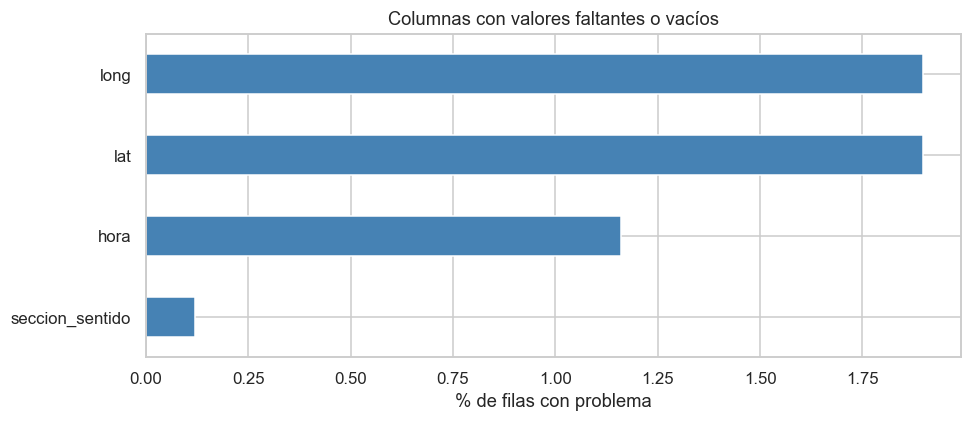

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
cols = nulls[nulls['pct_total'] > 0].index
if len(cols):
    nulls.loc[cols, 'pct_total'].sort_values().plot.barh(ax=ax, color='steelblue')
    ax.set_xlabel('% de filas con problema')
    ax.set_title('Columnas con valores faltantes o vacíos')
else:
    ax.text(0.5, 0.5, 'Sin valores faltantes', ha='center', va='center', transform=ax.transAxes)
plt.tight_layout()
plt.show()

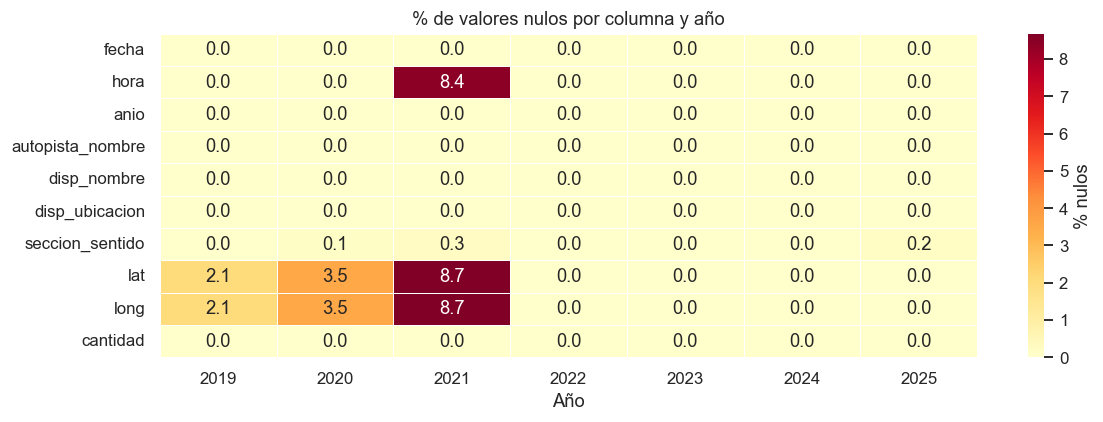

In [7]:
# Faltantes por año — mapa de calor
null_by_year = df.groupby('anio')[df.columns].apply(lambda g: g.isnull().mean() * 100)
fig, ax = plt.subplots(figsize=(11, 4))
sns.heatmap(null_by_year.T, annot=True, fmt='.1f', cmap='YlOrRd',
            linewidths=0.4, ax=ax, cbar_kws={'label': '% nulos'})
ax.set_title('% de valores nulos por columna y año')
ax.set_xlabel('Año')
plt.tight_layout()
plt.show()

## 4. Análisis de fechas y continuidad temporal

In [8]:
print('Rango de fechas:', df['fecha'].min().date(), '→', df['fecha'].max().date())
print('Fechas nulas:', df['fecha'].isnull().sum())

# Fechas cuyo año no coincide con la columna anio
mask_anio_incoh = df['fecha'].dt.year != df['anio'].astype('int64')
incoh = df[mask_anio_incoh & df['fecha'].notna()]
print(f'\nFechas con año incoherente (fecha.year ≠ anio): {len(incoh):,}')
if len(incoh):
    display(incoh[['fecha', 'anio', 'autopista_nombre']].value_counts().head(20))

Rango de fechas: 2019-01-01 → 2025-12-31
Fechas nulas: 0

Fechas con año incoherente (fecha.year ≠ anio): 20,003


fecha       anio  autopista_nombre 
2019-06-05  2020  AU 9 de Julio Sur    264
2019-06-06  2020  AU 9 de Julio Sur    264
2019-06-04  2020  AU 9 de Julio Sur    264
2019-06-13  2020  AU 9 de Julio Sur    264
2019-06-09  2020  AU 9 de Julio Sur    264
2019-06-10  2020  AU 9 de Julio Sur    264
2019-06-08  2020  AU 9 de Julio Sur    264
2019-06-07  2020  AU 9 de Julio Sur    264
2019-06-23  2020  AU 9 de Julio Sur    264
2019-06-24  2020  AU 9 de Julio Sur    264
2019-06-26  2020  AU 9 de Julio Sur    264
2019-06-25  2020  AU 9 de Julio Sur    264
2019-06-27  2020  AU 9 de Julio Sur    264
2019-06-20  2020  AU 9 de Julio Sur    264
2019-06-22  2020  AU 9 de Julio Sur    264
2019-06-21  2020  AU 9 de Julio Sur    264
2019-06-03  2020  AU 9 de Julio Sur    250
2019-06-19  2020  AU 9 de Julio Sur    246
2019-06-12  2020  AU 9 de Julio Sur    244
2019-06-14  2020  AU 9 de Julio Sur    236
Name: count, dtype: int64

In [9]:
# Días únicos por año
dias_por_anio = df.groupby('anio')['fecha'].nunique().rename('dias_únicos')
dias_esperados = pd.Series({
    2019: 365, 2020: 366, 2021: 365,
    2022: 365, 2023: 365, 2024: 366, 2025: 365
}, name='dias_esperados')
cobertura = pd.concat([dias_por_anio, dias_esperados], axis=1)
cobertura['faltantes'] = cobertura['dias_esperados'] - cobertura['dias_únicos']
cobertura['cobertura_%'] = cobertura['dias_únicos'] / cobertura['dias_esperados'] * 100
display(cobertura)

,dias_únicos,dias_esperados,faltantes,cobertura_%
2019,333,365,32,91.2329
2020,366,366,0,100.0000
2021,337,365,28,92.3288
2022,151,365,214,41.3699
2023,365,365,0,100.0000
2024,366,366,0,100.0000
2025,365,365,0,100.0000


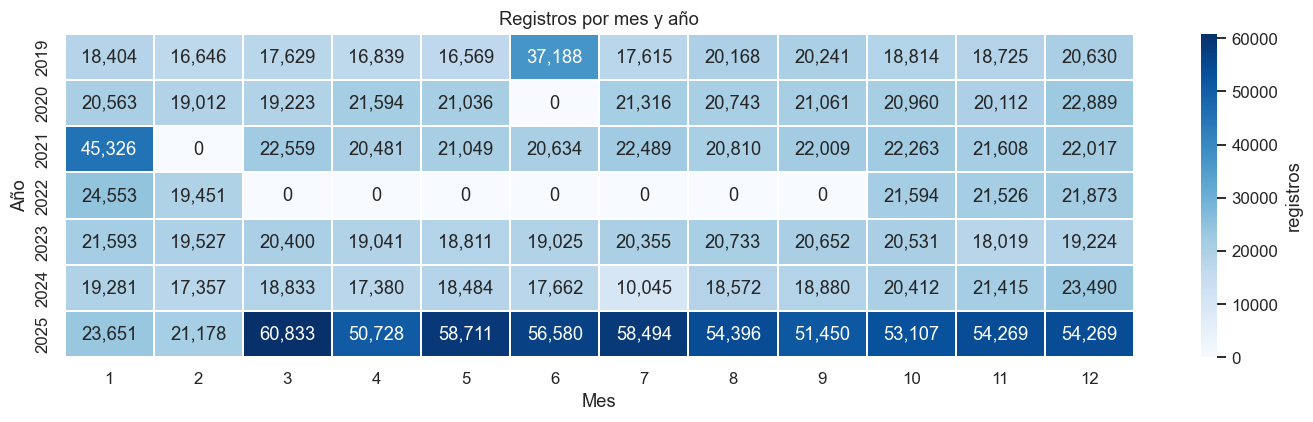

In [10]:
# Heatmap de registros por mes × año
df_valid = df.dropna(subset=['fecha'])
pivot = df_valid.groupby([df_valid['fecha'].dt.year.rename('año'),
                           df_valid['fecha'].dt.month.rename('mes')]).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(13, 4))
sns.heatmap(pivot, fmt=',d', annot=True, cmap='Blues', linewidths=0.3,
            ax=ax, cbar_kws={'label': 'registros'})
ax.set_title('Registros por mes y año')
ax.set_xlabel('Mes'); ax.set_ylabel('Año')
plt.tight_layout()
plt.show()

In [11]:
# Días sin ningún registro (huecos en la serie)
todos_los_dias = pd.date_range(df['fecha'].min(), df['fecha'].max(), freq='D')
dias_con_datos = set(df['fecha'].dropna().dt.normalize())
faltantes_global = [d for d in todos_los_dias if pd.Timestamp(d) not in dias_con_datos]
print(f'Días sin ningún registro en el dataset completo: {len(faltantes_global)}')
if faltantes_global:
    print('Primeros 20:', [str(d.date()) for d in faltantes_global[:20]])

Días sin ningún registro en el dataset completo: 300
Primeros 20: ['2019-01-22', '2019-01-28', '2019-01-29', '2019-01-30', '2019-01-31', '2019-02-27', '2019-02-28', '2019-03-21', '2019-03-28', '2019-03-29', '2019-03-30', '2019-03-31', '2019-04-06', '2019-04-13', '2019-04-14', '2019-04-30', '2019-05-04', '2019-05-10', '2019-05-11', '2019-05-18']


## 5. Variable objetivo: `cantidad`

In [12]:
cant = df['cantidad'].dropna()
print('Estadísticas de cantidad:')
print(cant.describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]))
print(f'\nCeros: {(cant == 0).sum():,} ({(cant == 0).mean()*100:.2f}%)')
print(f'Negativos: {(cant < 0).sum():,}')
print(f'> 100 000: {(cant > 100_000).sum():,}')

Estadísticas de cantidad:
count   1895607.0000
mean       2355.5034
std        2049.9687
min           0.0000
1%            0.0000
5%            6.0000
25%         594.0000
50%        1936.0000
75%        3615.0000
95%        6408.0000
99%        8226.0000
max       19936.0000
Name: cantidad, dtype: Float64

Ceros: 40,148 (2.12%)
Negativos: 0
> 100 000: 0


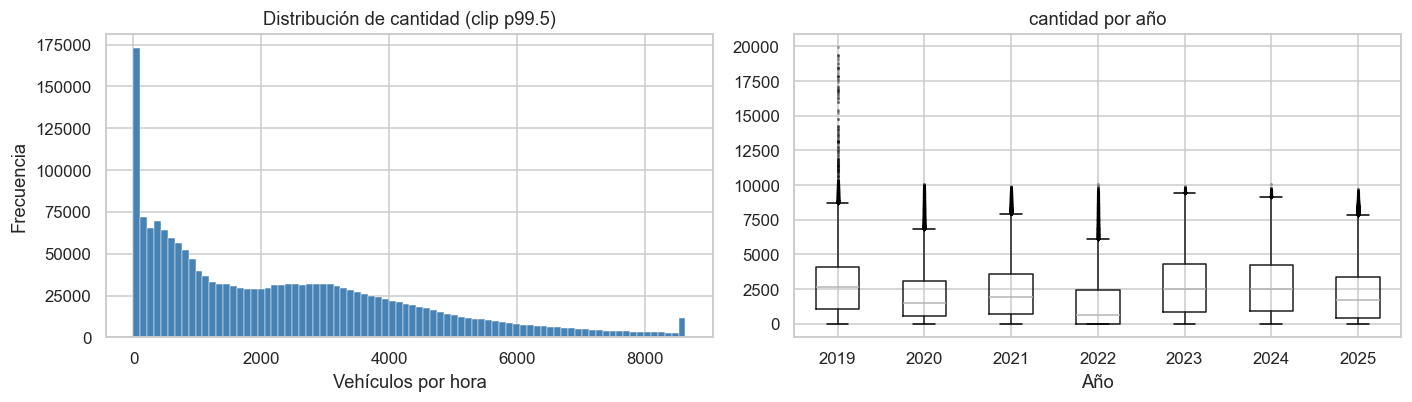

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Histograma
axes[0].hist(cant.clip(upper=cant.quantile(0.995)), bins=80, color='steelblue', edgecolor='white', linewidth=0.3)
axes[0].set_title('Distribución de cantidad (clip p99.5)')
axes[0].set_xlabel('Vehículos por hora'); axes[0].set_ylabel('Frecuencia')

# Boxplot por año
df.boxplot(column='cantidad', by='anio', ax=axes[1],
           flierprops=dict(marker='.', markersize=2, alpha=0.3))
axes[1].set_title('cantidad por año'); axes[1].set_xlabel('Año')
fig.suptitle('')
plt.tight_layout()
plt.show()

In [14]:
# Outliers extremos — registros con cantidad muy alta
umbral_alto = cant.quantile(0.9995)
print(f'Umbral p99.95: {umbral_alto:.0f}')
outliers_altos = df[df['cantidad'] > umbral_alto].copy()
print(f'Outliers extremos (>{umbral_alto:.0f}): {len(outliers_altos):,}')
if len(outliers_altos):
    display(outliers_altos[['fecha','hora','anio','autopista_nombre','disp_nombre','cantidad']]
            .sort_values('cantidad', ascending=False).head(20))

Umbral p99.95: 9564
Outliers extremos (>9564): 945


,fecha,hora,anio,autopista_nombre,disp_nombre,cantidad
141932,2019-09-02,7,2019,AU 4 Lugones,RD169 Monroe,19936.0000
205950,2019-12-11,7,2019,AU 4 Lugones,RD169 Monroe,19378.0000
141988,2019-09-02,9,2019,AU 4 Lugones,RD169 Monroe,19370.0000
141960,2019-09-02,8,2019,AU 4 Lugones,RD169 Monroe,19344.0000
141934,2019-09-02,7,2019,AU 4 Lugones,RD171 Esma,19184.0000
205951,2019-12-11,7,2019,AU 4 Lugones,RD170 Udaondo,19020.0000
141962,2019-09-02,8,2019,AU 4 Lugones,RD171 Esma,18834.0000
205952,2019-12-11,7,2019,AU 4 Lugones,RD171 Esma,18772.0000
141957,2019-09-02,8,2019,AU 4 Lugones,RD165 Dorrego,18508.0000
141990,2019-09-02,9,2019,AU 4 Lugones,RD171 Esma,18446.0000


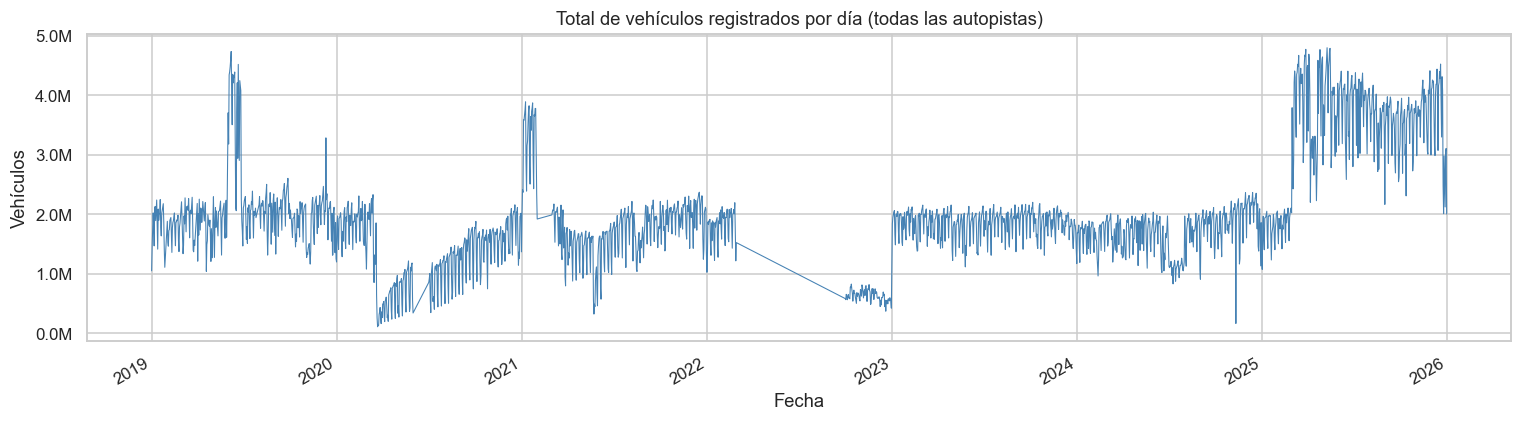

In [15]:
# Suma diaria total — serie de tiempo para detectar anomalías globales
daily = df.groupby('fecha')['cantidad'].sum().rename('total_vehiculos')
fig, ax = plt.subplots(figsize=(14, 4))
daily.plot(ax=ax, linewidth=0.7, color='steelblue')
ax.set_title('Total de vehículos registrados por día (todas las autopistas)')
ax.set_xlabel('Fecha'); ax.set_ylabel('Vehículos')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1e6:.1f}M'))
plt.tight_layout()
plt.show()

## 6. Variable `hora`

In [16]:
print('Valores únicos de hora:', sorted(df['hora'].dropna().unique().tolist()))
print('Fuera de rango [0,23]:', ((df['hora'] < 0) | (df['hora'] > 23)).sum())

Valores únicos de hora: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23]
Fuera de rango [0,23]: 0


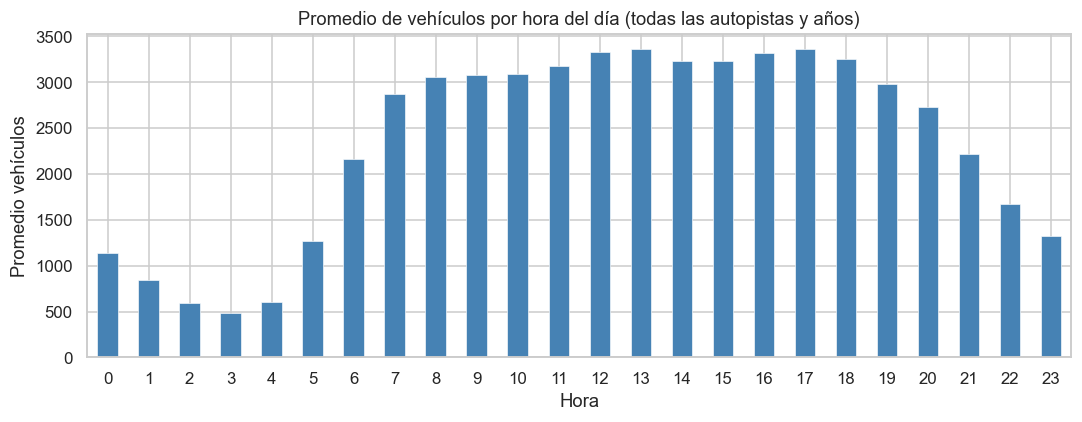

In [17]:
hora_media = df.groupby('hora')['cantidad'].mean()
fig, ax = plt.subplots(figsize=(10, 4))
hora_media.plot.bar(ax=ax, color='steelblue', edgecolor='white', linewidth=0.4)
ax.set_title('Promedio de vehículos por hora del día (todas las autopistas y años)')
ax.set_xlabel('Hora'); ax.set_ylabel('Promedio vehículos')
ax.set_xticks(range(24)); ax.set_xticklabels(range(24), rotation=0)
plt.tight_layout()
plt.show()

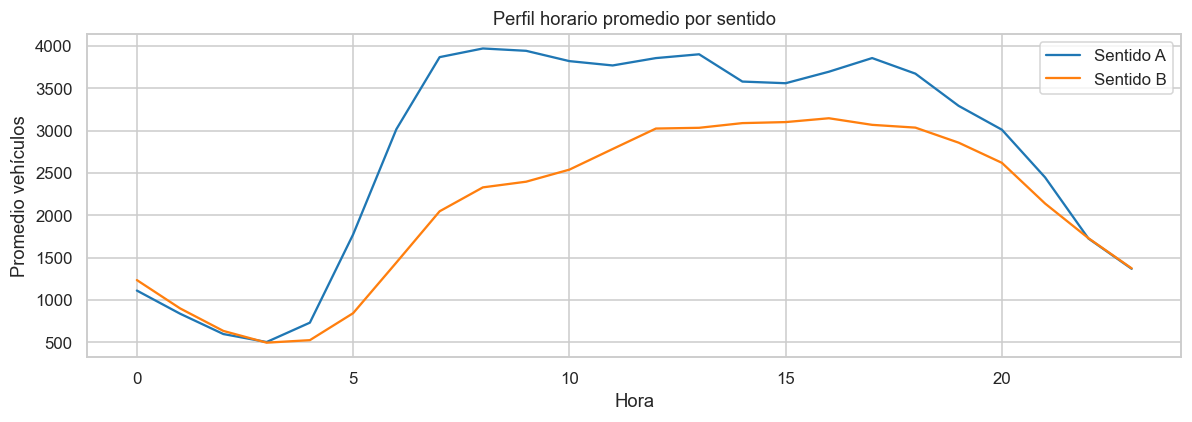

In [18]:
# Perfil horario por sentido
fig, ax = plt.subplots(figsize=(11, 4))
for sentido, grp in df[df['seccion_sentido'].isin(['A','B'])].groupby('seccion_sentido'):
    grp.groupby('hora')['cantidad'].mean().plot(ax=ax, label=f'Sentido {sentido}', linewidth=1.5)
ax.set_title('Perfil horario promedio por sentido')
ax.set_xlabel('Hora'); ax.set_ylabel('Promedio vehículos')
ax.legend()
plt.tight_layout()
plt.show()

## 7. Variables categóricas

In [19]:
# Autopistas
autop = df['autopista_nombre'].str.strip().value_counts()
print(f'Autopistas únicas: {autop.nunique()}')
display(autop.to_frame('registros'))

Autopistas únicas: 9


,registros
autopista_nombre,
AU Dellepiane,539610
AU 9 de Julio Sur,476286
AU 4 Lugones,310302
AU 5 Cantilo,204857
AU 25 de Mayo,181824
AU Perito Moreno (AU6),142746
AU 7 Campora,18836
AU 8 Illia B,14246
AU 8 Illia A,6900


In [20]:
# Autopistas con nombres inconsistentes (variantes del mismo nombre)
autop_norm = df['autopista_nombre'].str.strip().str.upper().str.replace(r'\s+', ' ', regex=True)
variantes = autop_norm.value_counts()
# Mostrar solo si hay discrepancia con el conteo sin normalizar
if len(variantes) != len(autop):
    print('Variantes encontradas tras normalizar mayúsculas/espacios:')
    display(variantes.to_frame('registros'))
else:
    print('Sin variantes de nombre detectadas.')

Sin variantes de nombre detectadas.


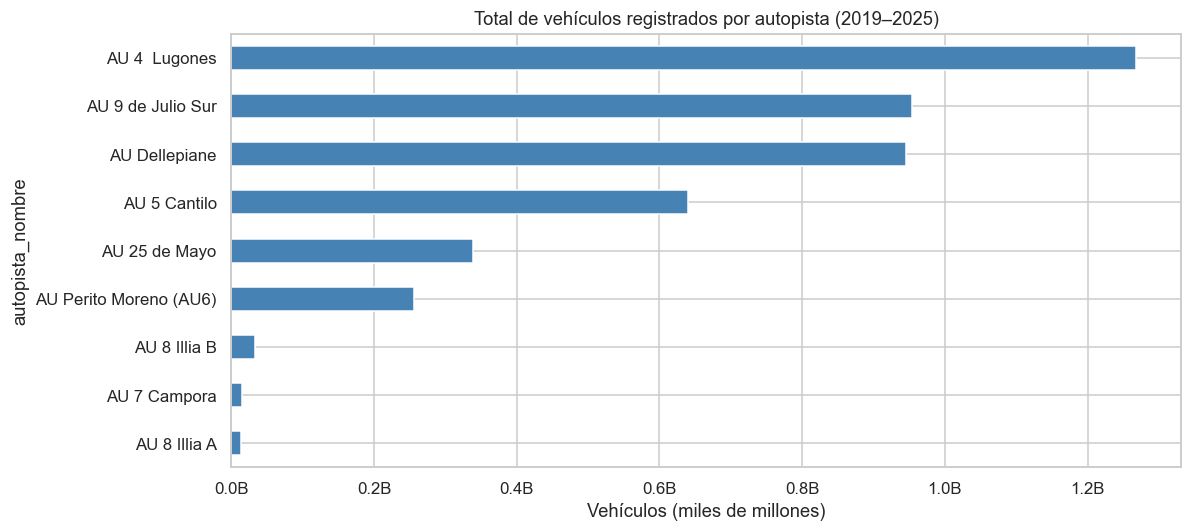

In [21]:
fig, ax = plt.subplots(figsize=(11, 5))
autop_sum = df.groupby('autopista_nombre')['cantidad'].sum().sort_values(ascending=True)
autop_sum.plot.barh(ax=ax, color='steelblue')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1e9:.1f}B'))
ax.set_title('Total de vehículos registrados por autopista (2019–2025)')
ax.set_xlabel('Vehículos (miles de millones)')
plt.tight_layout()
plt.show()

In [22]:
# Sentidos
sent = df['seccion_sentido'].value_counts(dropna=False)
print('Sentidos únicos:')
display(sent.to_frame('registros'))

Sentidos únicos:


,registros
seccion_sentido,
A,920707
B,913708
R,58928
NaN,2264


In [23]:
# Dispositivos (radares)
disp = df['disp_nombre'].value_counts()
print(f'Dispositivos únicos: {disp.nunique()}')
print('Top 20:')
display(disp.head(20).to_frame('registros'))

Dispositivos únicos: 62
Top 20:


,registros
disp_nombre,
RD134 Ituzaingo,106260
RD100 Montiel,96528
RD101 de la Torre,83970
RD103 Miralla,77765
RD106 Zinny,75859
RD111 Ramal 9,54774
RD180 Encalada,54238
RD168 Juramento,53954
RD166 Ombues,53931


In [24]:
# Dispositivos por autopista
disp_x_autop = df.groupby('autopista_nombre')['disp_nombre'].nunique().sort_values(ascending=False)
print('Dispositivos únicos por autopista:')
display(disp_x_autop.to_frame('dispositivos_únicos'))

Dispositivos únicos por autopista:


,dispositivos_únicos
autopista_nombre,
AU 9 de Julio Sur,15
AU Perito Moreno (AU6),13
AU 25 de Mayo,12
AU Dellepiane,9
AU 4 Lugones,6
AU 5 Cantilo,4
AU 8 Illia B,2
AU 8 Illia A,1
AU 7 Campora,1


In [25]:
# Dispositivos que aparecen solo en algunos años (detecta incorporaciones o bajas)
disp_anio = df.groupby('disp_nombre')['anio'].agg(set).apply(sorted)
no_completos = disp_anio[disp_anio.apply(len) < 7]
print(f'Dispositivos que NO aparecen en los 7 años: {len(no_completos)}')
display(no_completos.to_frame('años_con_datos').head(30))

Dispositivos que NO aparecen en los 7 años: 41


,años_con_datos
disp_nombre,
RD050 Gral. Paz B,[2025]
RD052 Acceso AU6,[2025]
RD053 Riach-AccNorte,[2025]
RD054 Barrag�n,[2025]
RD055 Velez,[2025]
RD056 Lope de Vega,[2025]
RD057 Rivadavia,[2025]
RD058 Rodo,[2025]
RD059 Remedios,[2025]


## 8. Variables geográficas (lat, long)

In [26]:
# Convertir a numérico
df['lat_f']  = pd.to_numeric(df['lat'],  errors='coerce')
df['long_f'] = pd.to_numeric(df['long'], errors='coerce')

print('lat nulas (incl. ya nulas):', df['lat_f'].isnull().sum())
print('long nulas:',                 df['long_f'].isnull().sum())
print()
print('Rango lat :', df['lat_f'].min(), '→', df['lat_f'].max())
print('Rango long:', df['long_f'].min(), '→', df['long_f'].max())

lat nulas (incl. ya nulas): 35961
long nulas: 35961

Rango lat : -346.699 → -34.5370899999987
Rango long: -584.464 → -58.36974


In [27]:
# Coordenadas fuera del área metropolitana de Buenos Aires
# Bounding box aproximada: lat [-35.0, -34.2], long [-59.0, -57.5]
fuera = df[(df['lat_f'].notna()) &
           ((df['lat_f'] < -35.0) | (df['lat_f'] > -34.2) |
            (df['long_f'] < -59.0) | (df['long_f'] > -57.5))]
print(f'Registros con coords fuera del AMBA: {len(fuera):,}')
if len(fuera):
    display(fuera[['fecha','anio','disp_nombre','lat','long','lat_f','long_f']].drop_duplicates(subset=['disp_nombre','lat_f','long_f']).head(20))

Registros con coords fuera del AMBA: 43,093


,fecha,anio,disp_nombre,lat,long,lat_f,long_f
480888,2021-01-01,2021,RD182 Labruna,-345.4230,NaN,-345.4230,NaN
493247,2021-01-01,2021,RD130 Suarez,-346.3940,NaN,-346.3940,NaN
494735,2021-01-01,2021,RD134 Ituzaingo,-346.3260,NaN,-346.3260,NaN
508107,2021-01-01,2021,RD103 Miralla,-346.6990,NaN,-346.6990,NaN
518368,2021-05-01,2021,RD181 Ciudad Univer.,-34.5436,-584.4640,-34.5436,-584.4640
519109,2021-05-01,2021,RD182 Labruna,-345.4230,-58.4487,-345.4230,-58.4487
524004,2021-05-01,2021,RD130 Suarez,-346.3940,-58.3764,-346.3940,-58.3764
525451,2021-05-01,2021,RD134 Ituzaingo,-346.3260,-58.3786,-346.3260,-58.3786
529210,2021-05-01,2021,RD103 Miralla,-346.6990,-58.4754,-346.6990,-58.4754
546956,2021-04-01,2021,RD134 Ituzaingo,-346.3260,-58.3786,-346.3260,-58.3786


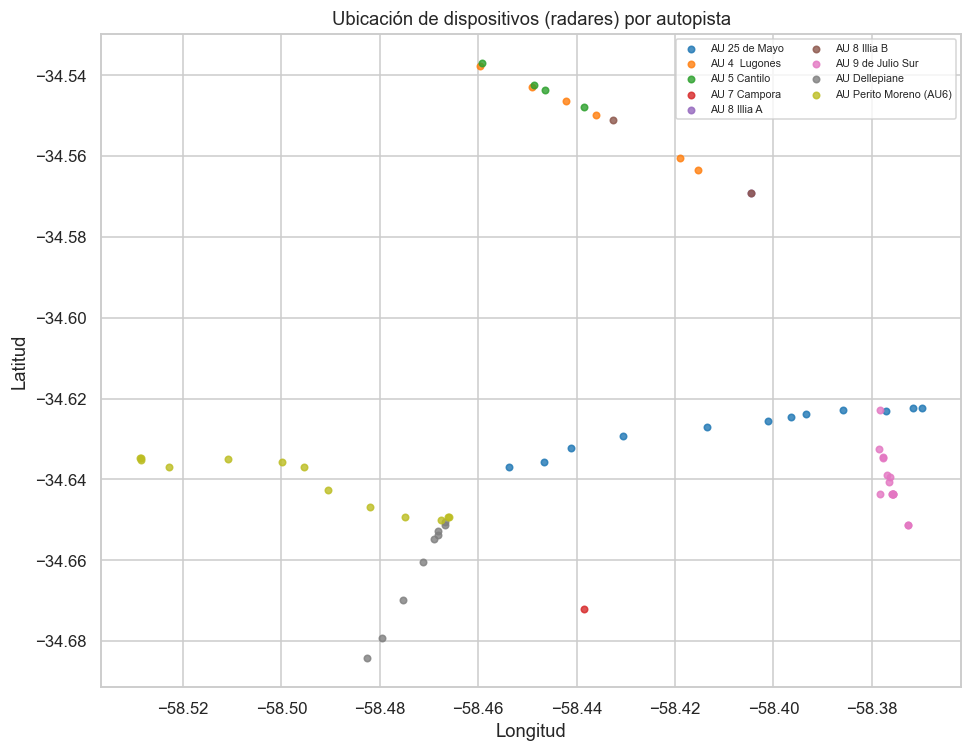

In [28]:
# Mapa de dispersión de dispositivos únicos
coords = df.dropna(subset=['lat_f','long_f']).groupby(['disp_nombre','autopista_nombre'])[['lat_f','long_f']].first().reset_index()
fig, ax = plt.subplots(figsize=(9, 7))
for autop_n, grp in coords.groupby('autopista_nombre'):
    ax.scatter(grp['long_f'], grp['lat_f'], label=autop_n, s=18, alpha=0.8)
ax.set_title('Ubicación de dispositivos (radares) por autopista')
ax.set_xlabel('Longitud'); ax.set_ylabel('Latitud')
ax.legend(loc='upper right', fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

In [29]:
# Inconsistencia: mismo dispositivo con coords distintas en distintos años
coord_por_disp = df.dropna(subset=['lat_f','long_f']) \
    .groupby('disp_nombre')[['lat_f','long_f']].nunique()
multiples_coords = coord_por_disp[(coord_por_disp['lat_f'] > 1) | (coord_por_disp['long_f'] > 1)]
print(f'Dispositivos con más de una coordenada: {len(multiples_coords)}')
if len(multiples_coords):
    display(multiples_coords)

Dispositivos con más de una coordenada: 32


,lat_f,long_f
disp_nombre,,
RD054 Barrag�n,2,2
RD058 Rodo,2,2
RD100 Montiel,3,2
RD103 Miralla,3,3
RD105 Homero,2,2
RD106 Zinny,4,4
RD108 Ramal a 27f.,4,5
RD110 Fernandez,4,3
RD111 Ramal 9,3,4


## 9. Reporte de calidad por año

In [30]:
def reporte_anio(g):
    n = len(g)
    return pd.Series({
        'filas':            n,
        'fecha_nula_%':     g['fecha'].isnull().mean() * 100,
        'lat_nula_%':       g['lat_f'].isnull().mean() * 100,
        'long_nula_%':      g['long_f'].isnull().mean() * 100,
        'cantidad_nula_%':  g['cantidad'].isnull().mean() * 100,
        'cantidad_cero_%':  (g['cantidad'] == 0).mean() * 100,
        'cant_media':       g['cantidad'].mean(),
        'cant_p99':         g['cantidad'].quantile(0.99),
        'cant_max':         g['cantidad'].max(),
        'sentido_nulo_%':   g['seccion_sentido'].isnull().mean() * 100,
        'disp_unicos':      g['disp_nombre'].nunique(),
        'dias_unicos':      g['fecha'].nunique(),
    })

reporte = df.groupby('anio').apply(reporte_anio)
display(reporte.style.background_gradient(cmap='YlOrRd', subset=[
    'fecha_nula_%','lat_nula_%','long_nula_%','cantidad_nula_%','cantidad_cero_%','sentido_nulo_%'
]))

C:\Users\santi\AppData\Local\Temp\ipykernel_19776\2584188054.py:18: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  reporte = df.groupby('anio').apply(reporte_anio)


,filas,fecha_nula_%,lat_nula_%,long_nula_%,cantidad_nula_%,cantidad_cero_%,cant_media,cant_p99,cant_max,sentido_nulo_%,disp_unicos,dias_unicos
anio,,,,,,,,,,,,
2019,219465.000000,0.000000,2.056820,2.056820,0.000000,0.401886,2918.545408,8863.360000,19936.000000,0.000000,28.000000,333.000000
2020,248512.000000,0.000000,3.534638,3.534638,0.000000,0.313063,1997.998451,7639.000000,10087.000000,0.137217,32.000000,366.000000
2021,261245.000000,0.000000,8.674999,8.674999,0.000000,0.647668,2390.196061,8207.000000,9963.000000,0.269479,29.000000,337.000000
2022,108997.000000,0.000000,0.000000,0.000000,0.000000,0.763324,1502.490234,7884.000000,10061.000000,0.000000,27.000000,151.000000
2023,237911.000000,0.000000,0.000000,0.000000,0.000000,1.961238,2836.278877,8524.000000,9947.000000,0.000000,25.000000,365.000000
2024,221811.000000,0.000000,0.000000,0.000000,0.000000,1.136553,2803.079067,8351.900000,10054.000000,0.000000,26.000000,366.000000
2025,597666.000000,0.000000,0.000000,0.000000,0.000000,4.814897,2080.315999,7516.350000,9681.000000,0.203960,56.000000,365.000000


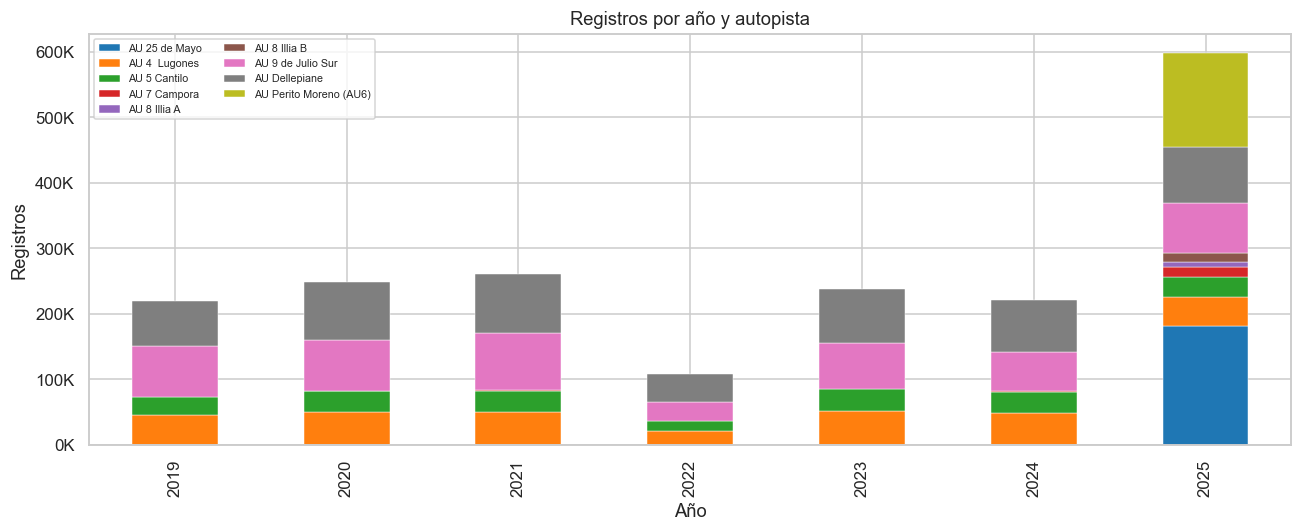

In [31]:
# Barras apiladas: filas por autopista × año
pivot_autop = df.groupby(['anio','autopista_nombre']).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(12, 5))
pivot_autop.plot.bar(ax=ax, stacked=True, edgecolor='white', linewidth=0.3)
ax.set_title('Registros por año y autopista')
ax.set_xlabel('Año'); ax.set_ylabel('Registros')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1e3:.0f}K'))
ax.legend(loc='upper left', fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

## 10. Saneamiento

In [32]:
# ── Paso 1: copiar para no mutar el original ──────────────────────────────────
clean = df.copy()
n0 = len(clean)
print(f'Filas iniciales: {n0:,}')

Filas iniciales: 1,895,607


In [33]:
# ── Paso 2: descartar filas sin fecha válida ──────────────────────────────────
clean = clean.dropna(subset=['fecha'])
print(f'Tras eliminar fecha nula: {len(clean):,} (−{n0-len(clean):,})')

Tras eliminar fecha nula: 1,895,607 (−0)


In [34]:
# ── Paso 3: corregir año derivándolo de la fecha ──────────────────────────────
# La columna anio del CSV ya es correcta, pero re-derivamos por consistencia
clean['anio'] = clean['fecha'].dt.year.astype('Int16')
print('Distribución final de anio:')
print(clean['anio'].value_counts().sort_index())

Distribución final de anio:
anio
2019    239468
2020    228509
2021    261245
2022    108997
2023    237911
2024    221811
2025    597666
Name: count, dtype: Int64


In [35]:
# ── Paso 4: normalizar texto ──────────────────────────────────────────────────
for col in ['autopista_nombre','disp_nombre','seccion_sentido']:
    clean[col] = clean[col].str.strip().str.replace(r'\s+', ' ', regex=True)

# Unificar variantes de nombre en autopistas (espacios dobles, etc.)
clean['autopista_nombre'] = clean['autopista_nombre'].str.replace(r'\s{2,}', ' ', regex=True)

# Sentido: solo A, B o R son valores esperados; el resto → NaN
sentidos_validos = {'A', 'B', 'R'}
mask_sent_inv = ~clean['seccion_sentido'].isin(sentidos_validos)
print(f'Sentidos inválidos → NaN: {mask_sent_inv.sum():,}')
print('Valores inválidos encontrados:', clean.loc[mask_sent_inv, 'seccion_sentido'].value_counts().head())
clean.loc[mask_sent_inv, 'seccion_sentido'] = pd.NA

Sentidos inválidos → NaN: 2,264
Valores inválidos encontrados: Series([], Name: count, dtype: int64)


In [36]:
# ── Paso 5: usar lat_f / long_f (numéricas) y descartar strings originales ────
clean = clean.drop(columns=['lat','long'])
clean = clean.rename(columns={'lat_f': 'lat', 'long_f': 'long'})

# Invalidar coords fuera del bounding box del AMBA
mask_coord_inv = (
    (clean['lat'] < -35.0) | (clean['lat'] > -34.2) |
    (clean['long'] < -59.0) | (clean['long'] > -57.5)
)
print(f'Coords fuera de AMBA → NaN: {mask_coord_inv.sum():,}')
clean.loc[mask_coord_inv, ['lat','long']] = np.nan

# Para 2021: lat siempre es NaN (dataset fuente no la tenía).
# Imputamos desde la coordenada modal del mismo dispositivo en otros años.
coord_modal = (
    clean[clean['lat'].notna()]
    .groupby('disp_nombre')[['lat','long']]
    .agg(lambda x: x.mode().iloc[0] if len(x.mode()) else np.nan)
)
faltantes_lat = clean['lat'].isna()
clean.loc[faltantes_lat, 'lat']  = clean.loc[faltantes_lat, 'disp_nombre'].map(coord_modal['lat'])
clean.loc[faltantes_lat, 'long'] = clean.loc[faltantes_lat, 'disp_nombre'].map(coord_modal['long'])
print(f'lat nulas tras imputación: {clean["lat"].isna().sum():,}')
print(f'long nulas tras imputación: {clean["long"].isna().sum():,}')

Coords fuera de AMBA → NaN: 43,831


lat nulas tras imputación: 0
long nulas tras imputación: 18,293


In [37]:
# ── Paso 6: disp_ubicacion → float ───────────────────────────────────────────
clean['disp_ubicacion'] = pd.to_numeric(clean['disp_ubicacion'], errors='coerce')
print('disp_ubicacion nulas:', clean['disp_ubicacion'].isna().sum())

disp_ubicacion nulas: 0


In [38]:
# ── Paso 7: cantidad — descartar negativos, cap outliers extremos ─────────────
neg = (clean['cantidad'] < 0).sum()
print(f'Negativos descartados: {neg:,}')
clean.loc[clean['cantidad'] < 0, 'cantidad'] = pd.NA

# Cap en p99.99 por año y autopista (outliers de sensor)
cap = clean.groupby(['anio','autopista_nombre'])['cantidad'].transform(lambda x: x.quantile(0.9999))
antes = (clean['cantidad'] > cap).sum()
clean['cantidad'] = clean['cantidad'].clip(upper=cap)
print(f'Valores capados en p99.99 (por año × autopista): {antes:,}')

# hora fuera de rango
hora_inv = ((clean['hora'] < 0) | (clean['hora'] > 23)).sum()
print(f'Horas fuera de [0,23] → NaN: {hora_inv:,}')
clean.loc[(clean['hora'] < 0) | (clean['hora'] > 23), 'hora'] = pd.NA

Negativos descartados: 0


Valores capados en p99.99 (por año × autopista): 207
Horas fuera de [0,23] → NaN: 0


In [39]:
# ── Paso 8: reordenar columnas ────────────────────────────────────────────────
col_order = ['fecha','anio','hora','autopista_nombre','disp_nombre',
             'disp_ubicacion','seccion_sentido','lat','long','cantidad']
clean = clean[col_order]
print(f'\nShape final: {clean.shape[0]:,} filas × {clean.shape[1]} columnas')
clean.dtypes


Shape final: 1,895,607 filas × 10 columnas


fecha               datetime64[ns]
anio                         Int16
hora                         Int16
autopista_nombre            object
disp_nombre                 object
disp_ubicacion             float64
seccion_sentido             object
lat                        float64
long                       float64
cantidad                   Float64
dtype: object

In [40]:
# ── Paso 9: resumen de cambios ────────────────────────────────────────────────
print('=== RESUMEN DE SANEAMIENTO ===')
print(f'  Filas originales:            {n0:,}')
print(f'  Filas finales:               {len(clean):,}')
print(f'  Eliminadas (fecha nula):     {n0 - len(clean):,}')
print()
print('Nulos remanentes por columna:')
display(clean.isnull().sum().to_frame('nulos_remanentes'))

=== RESUMEN DE SANEAMIENTO ===
  Filas originales:            1,895,607
  Filas finales:               1,895,607
  Eliminadas (fecha nula):     0

Nulos remanentes por columna:


,nulos_remanentes
fecha,0
anio,0
hora,22017
autopista_nombre,0
disp_nombre,0
disp_ubicacion,0
seccion_sentido,2264
lat,0
long,18293
cantidad,0


In [41]:
# ── Paso 10: exportar CSV limpio ─────────────────────────────────────────────
clean.to_csv(DST, index=False, date_format='%Y-%m-%d')
size_mb = DST.stat().st_size / 1e6
print(f'Exportado: {DST.name}  ({size_mb:.1f} MB)')

Exportado: flujo-vehicular-limpio.csv  (163.7 MB)


## 11. Validación post-saneamiento

In [42]:
# Verificación de integridad del CSV exportado
check = pd.read_csv(DST, parse_dates=['fecha'], low_memory=False)
print(f'Filas leídas del CSV limpio: {len(check):,}')
assert len(check) == len(clean), 'MISMATCH en número de filas'

print('\nNulos por columna en el CSV limpio:')
display(check.isnull().sum().to_frame('nulos'))

print('\nPrimeras filas:')
display(check.head())

Filas leídas del CSV limpio: 1,895,607

Nulos por columna en el CSV limpio:


,nulos
fecha,0
anio,0
hora,22017
autopista_nombre,0
disp_nombre,0
disp_ubicacion,0
seccion_sentido,2264
lat,0
long,18293
cantidad,0



Primeras filas:


,fecha,anio,hora,autopista_nombre,disp_nombre,disp_ubicacion,seccion_sentido,lat,long,cantidad
0,2019-01-01,2019,0.0000,AU 4 Lugones,RD165 Dorrego,4.7400,A,-34.5634,-58.4153,618.0000
1,2019-01-01,2019,0.0000,AU 4 Lugones,RD166 Ombues,5.5000,A,-34.5604,-58.4191,797.0000
2,2019-01-01,2019,0.0000,AU 4 Lugones,RD168 Juramento,7.2000,A,-34.5498,-58.4360,66.0000
3,2019-01-01,2019,0.0000,AU 4 Lugones,RD169 Monroe,8.1100,A,-34.5463,-58.4422,857.0000
4,2019-01-01,2019,0.0000,AU 4 Lugones,RD170 Udaondo,8.6800,A,-34.5429,-58.4490,861.0000


In [43]:
# Distribución final por año
final_x_anio = check.groupby('anio').agg(
    filas=('fecha','count'),
    dias=('fecha','nunique'),
    vehiculos=('cantidad','sum'),
    cant_media=('cantidad','mean'),
    dispositivos=('disp_nombre','nunique')
)
display(final_x_anio)

,filas,dias,vehiculos,cant_media,dispositivos
anio,,,,,
2019,239468,337,698603111.9196,2917.3130,28
2020,228509,336,438423332.8899,1918.6261,31
2021,261245,337,624424813.5390,2390.1886,29
2022,108997,151,163766111.9404,1502.4827,27
2023,237911,365,674779768.0893,2836.2697,25
2024,221811,366,621751481.4129,2803.0687,26
2025,597666,365,1243324239.9115,2080.2994,56


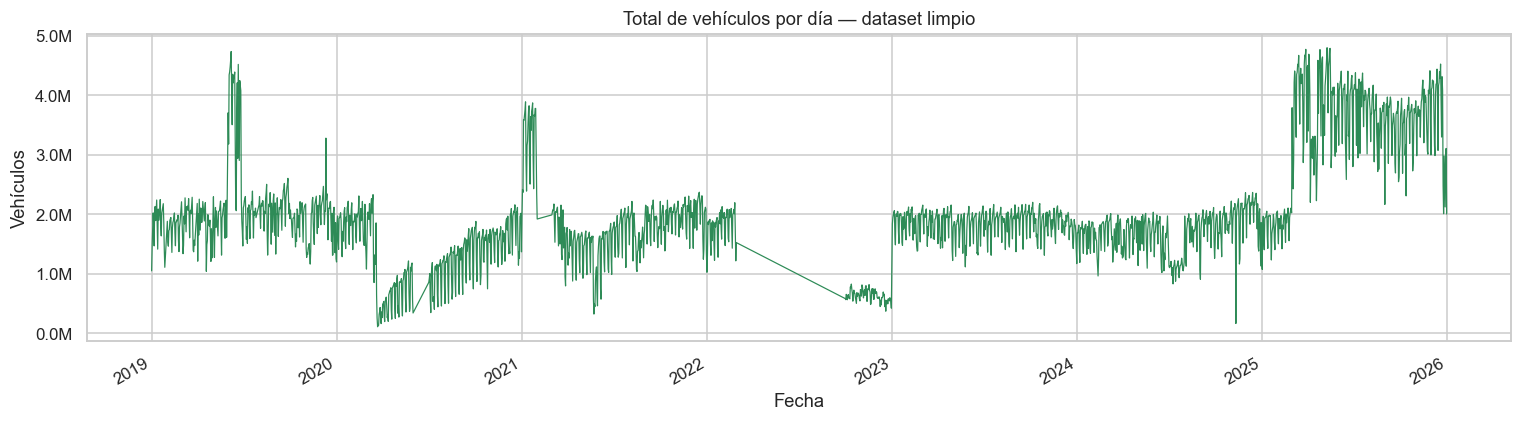

In [44]:
# Curva final de vehiculos por día (limpio)
daily_clean = check.groupby('fecha')['cantidad'].sum()
fig, ax = plt.subplots(figsize=(14, 4))
daily_clean.plot(ax=ax, linewidth=0.8, color='seagreen')
ax.set_title('Total de vehículos por día — dataset limpio')
ax.set_xlabel('Fecha'); ax.set_ylabel('Vehículos')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1e6:.1f}M'))
plt.tight_layout()
plt.show()